In [1]:
# Imports, chargement des CSV dans train et test
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'data/test.csv'

In [ ]:
# Dimensions (lignes, colonnes) : test a une colonne de moins (Survived)
train.shape, test.shape

((891, 12), (418, 11))

In [ ]:
# Types des colonnes et nombre de valeurs non nulles dans train
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [ ]:
# Idem pour test
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


In [ ]:
# 5 premières lignes de train
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# 10 premières lignes de train
train.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


Valeurs null par variables

In [ ]:
# Valeurs manquantes (nombre et %) dans train et test
pd.DataFrame({
    "train": train.isna().sum(),
    "train_%": (train.isna().mean() * 100).round(1),
    "test": test.isna().sum(),
    "test_%": (test.isna().mean() * 100).round(1),
})

,train,train_%,test,test_%
Age,177,19.9,86.0,20.6
Cabin,687,77.1,327.0,78.2
Embarked,2,0.2,0.0,0.0
Fare,0,0.0,1.0,0.2
Name,0,0.0,0.0,0.0
Parch,0,0.0,0.0,0.0
PassengerId,0,0.0,0.0,0.0
Pclass,0,0.0,0.0,0.0
Sex,0,0.0,0.0,0.0
SibSp,0,0.0,0.0,0.0


Doublons

In [ ]:
# Nombre de lignes en double dans train et test
train.duplicated().sum(), test.duplicated().sum()

(np.int64(0), np.int64(0))

In [ ]:
# Résumé des colonnes texte puis numériques de train
print(train.describe(include="object"))
print(train.describe())

                           Name   Sex  Ticket Cabin Embarked
count                       891   891     891   204      889
unique                      891     2     681   147        3
top     Braund, Mr. Owen Harris  male  347082    G6        S
freq                          1   577       7     4      644
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  


/var/folders/sd/_747tl1942g3lfv8k11wjtxc0000gn/T/ipykernel_81379/753960829.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(train.describe(include="object"))


In [ ]:
# Résumé statistique des colonnes numériques de train
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Impact variables sur le target

In [ ]:
# Part de morts (0) et de survivants (1) en %
(train["Survived"].value_counts(normalize=True) * 100).round(1)

Survived
0    61.6
1    38.4
Name: proportion, dtype: float64

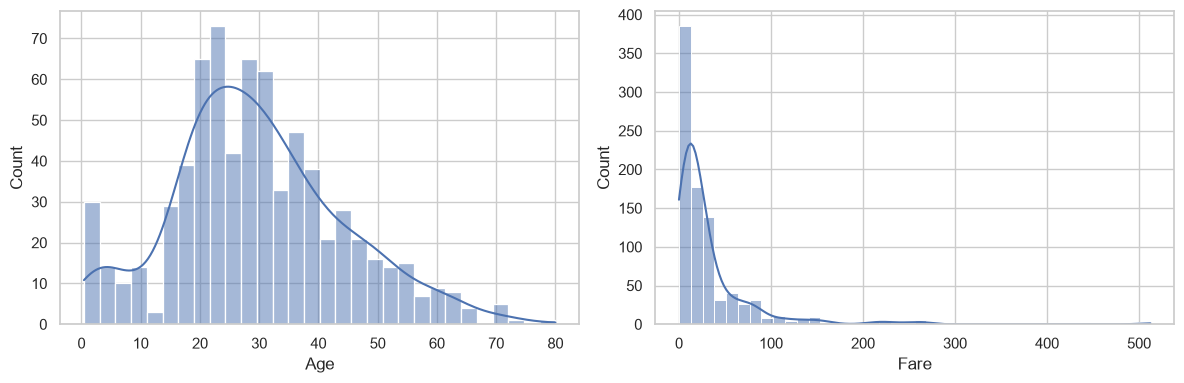

In [ ]:
# Distribution de Age (gauche) et de Fare (droite)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["Age"].dropna(), bins=30, kde=True, ax=axes[0])
sns.histplot(train["Fare"], bins=40, kde=True, ax=axes[1])
plt.tight_layout()
plt.show()

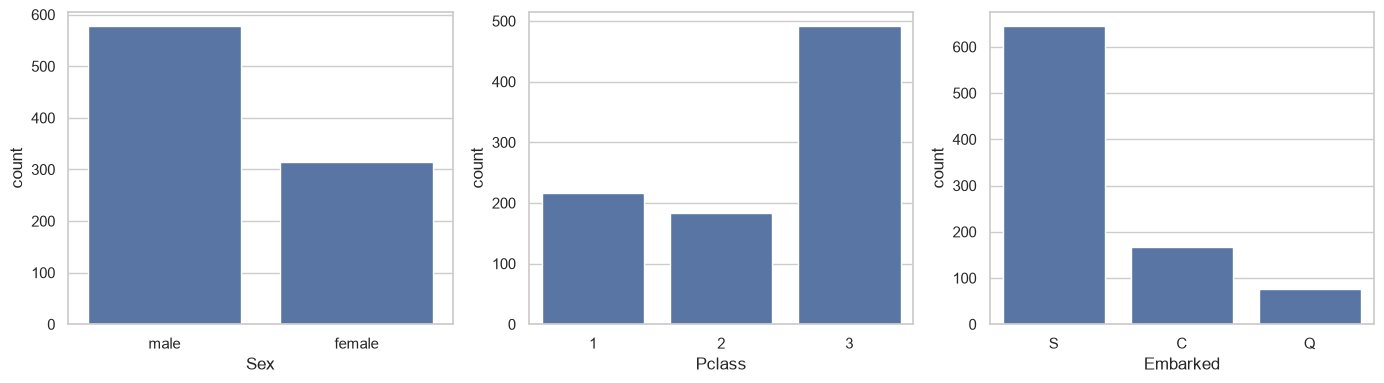

In [ ]:
# Répartition des passagers par Sex, Pclass et Embarked
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.countplot(data=train, x=col, ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
# Taux de survie (%) selon le sexe
train.groupby("Sex")["Survived"].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [ ]:
# Taux de survie (%) selon la classe
train.groupby("Pclass")["Survived"].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

In [ ]:
# Taux de survie (%) selon le port d'embarquement
train.groupby("Embarked")["Survived"].mean() * 100

Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64

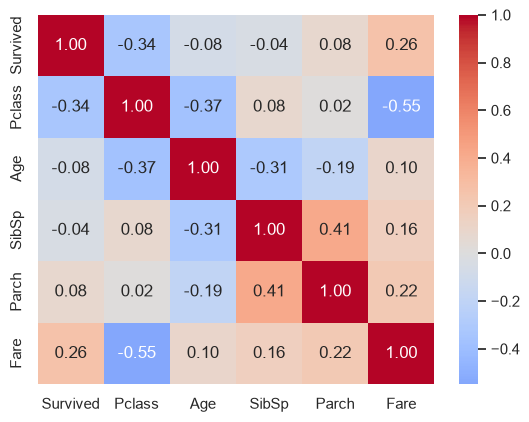

In [ ]:
# Corrélations entre variables numériques de train
sns.heatmap(train.select_dtypes("number").drop(columns="PassengerId").corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()